<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

P(Rain): 0.5
P(Wet Grass): 0.65
P(Rain AND Wet Grass): 0.4581

Probability of Rain given Wet Grass: 0.7048
Percentage: 70.48 %


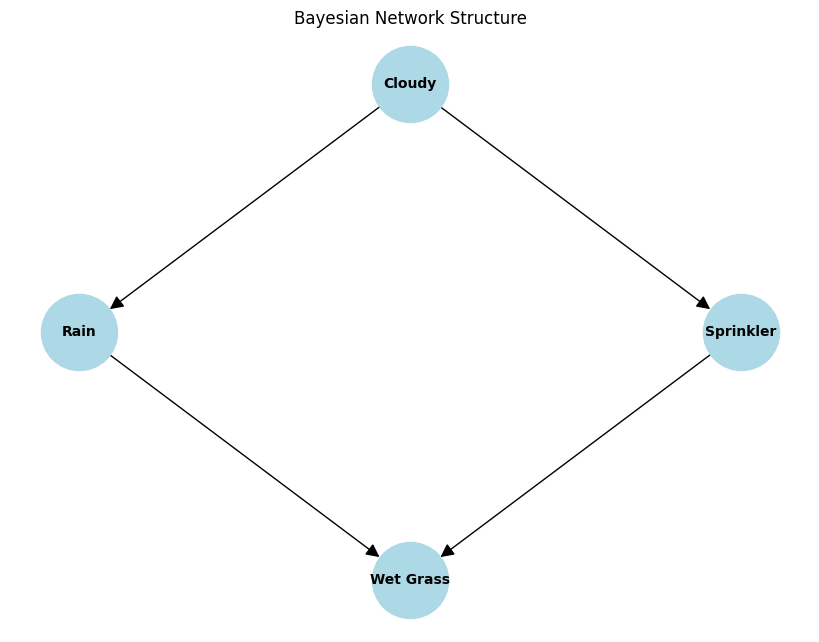

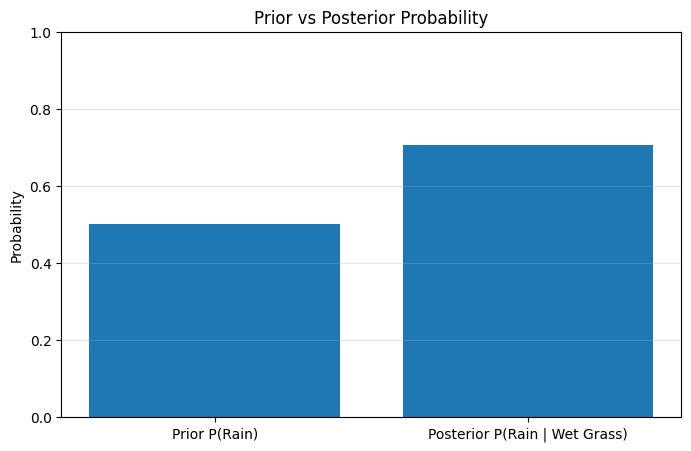

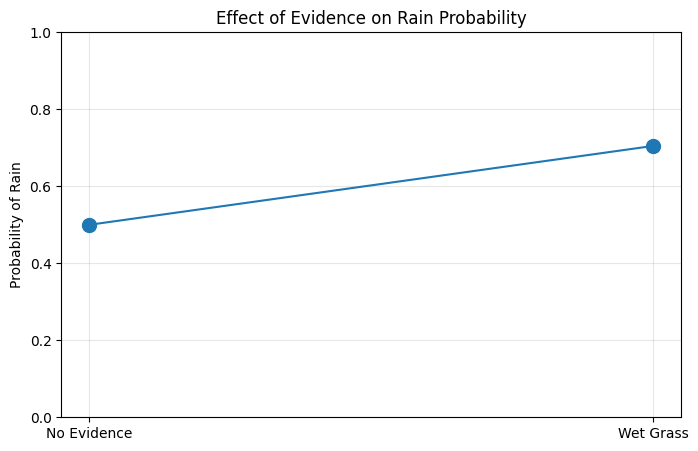


Bayesian Network Completed!
When grass is wet, probability of rain is 70.48 %


In [ ]:

# PROGRAM 9: BAYESIAN NETWORKS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from itertools import product

# --------------------------------
# 1. DEFINE BAYESIAN NETWORK
# --------------------------------

# Variables:
# C = Cloudy
# R = Rain
# S = Sprinkler
# W = Wet Grass

# Network structure:
# Cloudy -> Rain
# Cloudy -> Sprinkler
# Rain -> Wet Grass
# Sprinkler -> Wet Grass

# --------------------------------
# 2. DEFINE CONDITIONAL PROBABILITIES
# --------------------------------

# P(Cloudy)
P_C = {True: 0.5, False: 0.5}

# P(Rain | Cloudy)
P_R_C = {
    True: 0.8,
    False: 0.2
}

# P(Sprinkler | Cloudy)
P_S_C = {
    True: 0.1,
    False: 0.5
}

# P(WetGrass | Rain, Sprinkler)
P_W_RS = {
    (True, True): 0.99,
    (True, False): 0.90,
    (False, True): 0.90,
    (False, False): 0.01
}

# --------------------------------
# 3. CALCULATE JOINT PROBABILITY
# --------------------------------

def joint_probability(c, r, s, w):

    p = P_C[c]

    # Probability of Rain given Cloudy
    p *= P_R_C[c] if r else (1 - P_R_C[c])

    # Probability of Sprinkler given Cloudy
    p *= P_S_C[c] if s else (1 - P_S_C[c])

    # Probability of Wet Grass given Rain and Sprinkler
    prob_wet = P_W_RS[(r, s)]

    p *= prob_wet if w else (1 - prob_wet)

    return p


# --------------------------------
# 4. CALCULATE EVENT PROBABILITIES
# --------------------------------

# Calculate P(Rain)
P_Rain = sum(
    joint_probability(c, r, s, w)
    for c, r, s, w in product([True, False], repeat=4)
    if r
)

# Calculate P(Wet Grass)
P_Wet = sum(
    joint_probability(c, r, s, w)
    for c, r, s, w in product([True, False], repeat=4)
    if w
)

# Calculate P(Rain AND Wet Grass)
P_Rain_Wet = sum(
    joint_probability(c, r, s, w)
    for c, r, s, w in product([True, False], repeat=4)
    if r and w
)

# Bayes' Theorem
P_Rain_given_Wet = P_Rain_Wet / P_Wet

print("P(Rain):", round(P_Rain, 4))
print("P(Wet Grass):", round(P_Wet, 4))
print("P(Rain AND Wet Grass):", round(P_Rain_Wet, 4))

print(
    "\nProbability of Rain given Wet Grass:",
    round(P_Rain_given_Wet, 4)
)

print(
    "Percentage:",
    round(P_Rain_given_Wet * 100, 2), "%"
)


# --------------------------------
# 5. BAYESIAN NETWORK GRAPH
# --------------------------------

G = nx.DiGraph()

G.add_edges_from([
    ("Cloudy", "Rain"),
    ("Cloudy", "Sprinkler"),
    ("Rain", "Wet Grass"),
    ("Sprinkler", "Wet Grass")
])

pos = {
    "Cloudy": (0.5, 1),
    "Rain": (0, 0.5),
    "Sprinkler": (1, 0.5),
    "Wet Grass": (0.5, 0)
}

plt.figure(figsize=(8, 6))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=3000,
    node_color='lightblue',
    font_size=10,
    font_weight='bold',
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network Structure")
plt.show()


# --------------------------------
# 6. PRIOR VS POSTERIOR PROBABILITY
# --------------------------------

probabilities = [
    P_Rain,
    P_Rain_given_Wet
]

labels = [
    "Prior P(Rain)",
    "Posterior P(Rain | Wet Grass)"
]

plt.figure(figsize=(8, 5))

plt.bar(
    labels,
    probabilities
)

plt.ylabel("Probability")
plt.title("Prior vs Posterior Probability")
plt.ylim(0, 1)

plt.grid(axis='y', alpha=0.3)
plt.show()


# --------------------------------
# 7. CONDITIONAL PROBABILITY GRAPH
# --------------------------------

conditions = [
    ("No Evidence", P_Rain),
    ("Wet Grass", P_Rain_given_Wet)
]

names = [item[0] for item in conditions]
values = [item[1] for item in conditions]

plt.figure(figsize=(8, 5))

plt.plot(
    names,
    values,
    marker='o',
    markersize=10
)

plt.ylabel("Probability of Rain")
plt.title("Effect of Evidence on Rain Probability")
plt.ylim(0, 1)

plt.grid(True, alpha=0.3)
plt.show()


# --------------------------------
# 8. FINAL RESULT
# --------------------------------

print("\nBayesian Network Completed!")

print(
    "When grass is wet, probability of rain is",
    round(P_Rain_given_Wet * 100, 2), "%"
)
